# A08 道路封闭或拥堵后，怎样修订剩余计划？

机器人在出发后才逐步获知封路和拥堵。比较坚持原计划、道路不可行时修订、每到节点重新计算三种规则；所有规则收到相同时间发生的信息。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 建立道路和公开的事件机制
图的weight表示当前已知通行时间。事件按模拟时间发生，策略只能在到达节点时观察；不得提前把未来封路泄露给规划器。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

import networkx as nx
initial=nx.Graph()
initial.add_weighted_edges_from([("S","A",1),("A","G",1),("A","B",1),("B","G",3),("B","C",1),("C","G",1),("S","B",3)])
events=[dict(time=1,kind="close",u="A",v="G"),dict(time=2,kind="cost",u="B",v="C",value=9)]
def observe(graph,clock,applied):
    messages=[]
    for k,event in enumerate(events):
        if k in applied or event["time"]>clock: continue
        if event["kind"]=="close": graph.remove_edge(event["u"],event["v"])
        else: graph[event["u"]][event["v"]]["weight"]=event["value"]
        applied.add(k);messages.append(event["kind"]+":"+event["u"]+"-"+event["v"])
    return messages
old_path=nx.shortest_path(initial,"S","G",weight="weight")
(DATA_DIR/"事件.json").write_text(json.dumps(events,indent=2),encoding="utf-8")


161

## 2. 三种反馈规则共用一个执行环境
每轮先观测，再决定是否重算，再执行下一段。已经走过的历史固定。修改量统计为未来路线发生变化的次数，并不把一次函数调用当成真正修改。

In [3]:
def execute(policy):
    graph=initial.copy();applied=set();clock=0;node="S";planned=list(old_path);trace=[];changes=0
    for step in range(20):
        news=observe(graph,clock,applied)
        if node=="G": return dict(policy=policy,success=True,time=clock,changes=changes,trace=trace)
        legal=all(graph.has_edge(u,v) for u,v in zip(planned,planned[1:]))
        should_replan=policy=="rolling" or (policy=="repair_blocked" and not legal)
        if should_replan:
            try: replacement=nx.shortest_path(graph,node,"G",weight="weight")
            except nx.NetworkXNoPath: return dict(policy=policy,success=False,time=clock,changes=changes,trace=trace,reason="NO_PATH_CURRENT_MAP")
            changes+=int(replacement!=planned);planned=replacement
        if len(planned)<2 or not graph.has_edge(node,planned[1]):
            return dict(policy=policy,success=False,time=clock,changes=changes,trace=trace,reason="OLD_PLAN_INFEASIBLE")
        nxt=planned[1];duration=graph[node][nxt]["weight"]
        trace.append(dict(step=step,start=clock,origin=node,target=nxt,duration=duration,news=";".join(news)))
        clock+=duration;node=nxt;planned=planned[1:]
    return dict(policy=policy,success=False,time=clock,changes=changes,trace=trace,reason="EXECUTION_LIMIT")
results=[execute(p) for p in ["fixed","repair_blocked","rolling"]]
assert not results[0]["success"]
assert results[1]["success"] and results[2]["success"]


## 3. 按实际观测时刻复核执行轨迹
检查器重新播放事件，验证每条路当时确实可通行且使用当时的耗时。它不从策略的文字解释判断对错。

In [4]:
def verify_execution(result):
    graph=initial.copy();applied=set();clock=0;location="S"
    for row in result["trace"]:
        observe(graph,clock,applied)
        if row["origin"]!=location or row["start"]!=clock: return False
        if not graph.has_edge(location,row["target"]): return False
        if row["duration"]!=graph[location][row["target"]]["weight"]: return False
        clock+=row["duration"];location=row["target"]
    return clock==result["time"] and (not result["success"] or location=="G")
assert all(verify_execution(r) for r in results)
assert results[2]["time"]<results[1]["time"]
# 原计划失败耗时不是可执行方案的总成本，图中标成未完成。
summary=pd.DataFrame([{k:v for k,v in r.items() if k!="trace"} for r in results])


## 4. 给出触发规则和局限
周期重算多花计算，不应只看路线更短。这里图很小，完整实验仍记录计算次数/修改次数；更大场景要加入实际求解时间和改计划的组织成本。

In [5]:
summary.to_csv(OUT_DIR/"策略对照.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([dict(policy=r["policy"],**row) for r in results for row in r["trace"]]).to_csv(OUT_DIR/"执行记录.csv",index=False,encoding="utf-8-sig")
successful=[r for r in results if r["success"]]
plt.bar([r["policy"] for r in successful],[r["time"] for r in successful]);plt.ylabel("完成任务的实际耗时")
plt.title("固定旧计划未完成，不作为有效低成本方案")
plt.tight_layout();plt.savefig(OUT_DIR/"重规划.png");plt.close()
best=min(successful,key=lambda r:r["time"])
save_results({"strategies":[{k:v for k,v in r.items() if k!="trace"} for r in results]},
             f"本情景推荐{best['policy']}，实际耗时{best['time']}、修改{best['changes']}次。"
             "仅在封路时修复会忽视仍可通行但变慢的道路；可将成本明显变化也设为事件触发。"
             "本例是图上反馈重规划，没有声称具备连续控制MPC的稳定性保证。")


{
  "strategies": [
    {
      "policy": "fixed",
      "success": false,
      "time": 1,
      "changes": 0,
      "reason": "OLD_PLAN_INFEASIBLE"
    },
    {
      "policy": "repair_blocked",
      "success": true,
      "time": 12,
      "changes": 1
    },
    {
      "policy": "rolling",
      "success": true,
      "time": 5,
      "changes": 2
    }
  ]
}
本情景推荐rolling，实际耗时5、修改2次。仅在封路时修复会忽视仍可通行但变慢的道路；可将成本明显变化也设为事件触发。本例是图上反馈重规划，没有声称具备连续控制MPC的稳定性保证。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

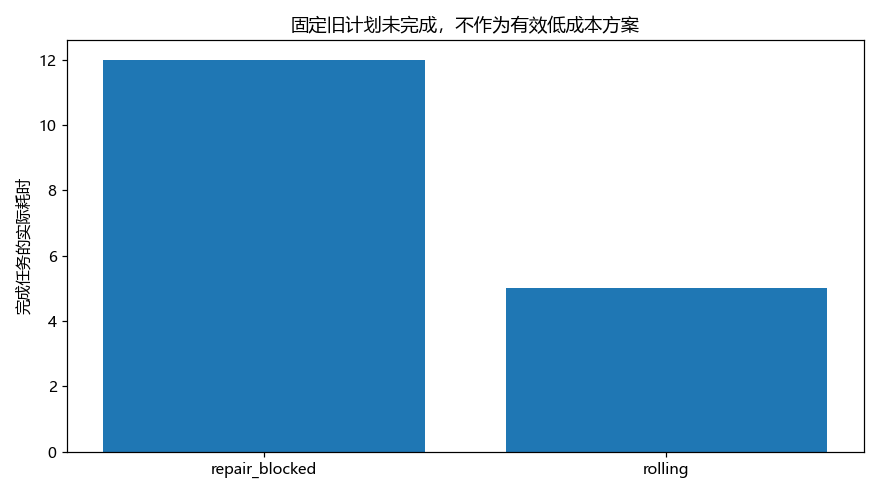

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
此教学环境假设到达节点时观测，通行中耗时不再变化。周期重算与事件触发哪种更好取决于信息更新、计算成本和变更成本。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。